# Notebook 03 - Feature Selection (Leakage Analysis & Importance Ranking)

This notebook unifies the data refinement pipeline:
1. **Part 1: Feature Leakage Analysis** - Identifies and excises 22 target-leakage and post-event synthetic attributes.
2. **Part 2: Feature Importance & Selection** - Evaluates Random Forest Gini importance to select the definitive 20 canonical features.

## Part 1: Feature Leakage Analysis
Auditing preprocessed telematics data for downstream or synthetic target leakage.

In [1]:
import pandas as pd

df = pd.read_csv("data/processed/preprocessed_dataset.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (250000, 51)


,Vehicle_ID,Make_and_Model,Vehicle_Type,Year_of_Manufacture,Route_Info,Weather_Conditions,Road_Conditions,Communication_Interface,Telematics_Gateway,Edge_Device_Class,...,CMES,UER,Predictive_Score,Pre_Event_Record,Data_Split,FL_Client_ID,Partition_Type,Local_Epochs_Per_Round,Communication_Rounds,is_noisy
0,1,1,4,2016.118444,1,4,4,1,2,2,...,1.374778,62.557204,0.161234,1,1,1,0,2,200,1
1,2,0,2,2016.595755,1,5,3,2,0,3,...,3.190890,29.707607,0.164251,1,0,1,0,2,200,1
2,3,3,3,2011.291703,1,4,0,2,0,1,...,0.556261,76.309671,0.194853,1,1,2,0,2,200,1
3,4,4,0,2020.365600,0,5,1,0,2,0,...,1.047579,45.339844,0.161826,1,1,3,0,2,200,1
4,5,4,1,2023.241627,1,4,2,2,2,3,...,4.275886,3.764722,0.204831,1,1,4,0,2,200,1


In [2]:
corr = df.corr(numeric_only=True)

target_corr = (
    corr["Maintenance_Required"]
    .sort_values(ascending=False)
)

target_corr

Maintenance_Required             1.000000
Maintenance_Severity_ID          0.789806
Predictive_Score                 0.742314
Impact_on_Efficiency             0.693166
Fuel_Consumption                 0.690003
Days_Since_Last_Maintenance      0.685230
TPI                              0.676694
CMES                             0.676593
Vibration_Levels                 0.667614
Engine_Temperature               0.652083
Downtime_Maintenance             0.643424
ADS                              0.629938
Historical_Maintenance_Cost      0.624720
Maintenance_Cost                 0.624393
CAN_Message_Rate_Hz              0.620602
Sensor_Packet_Loss_Rate          0.608826
Anomalies_Detected               0.574802
PCR                              0.573802
MBF                              0.567253
Diagnostic_Trouble_Code_Count    0.559661
Failure_History                  0.525561
OHI                              0.292342
FL_Client_ID                     0.215392
Actual_Load                      0

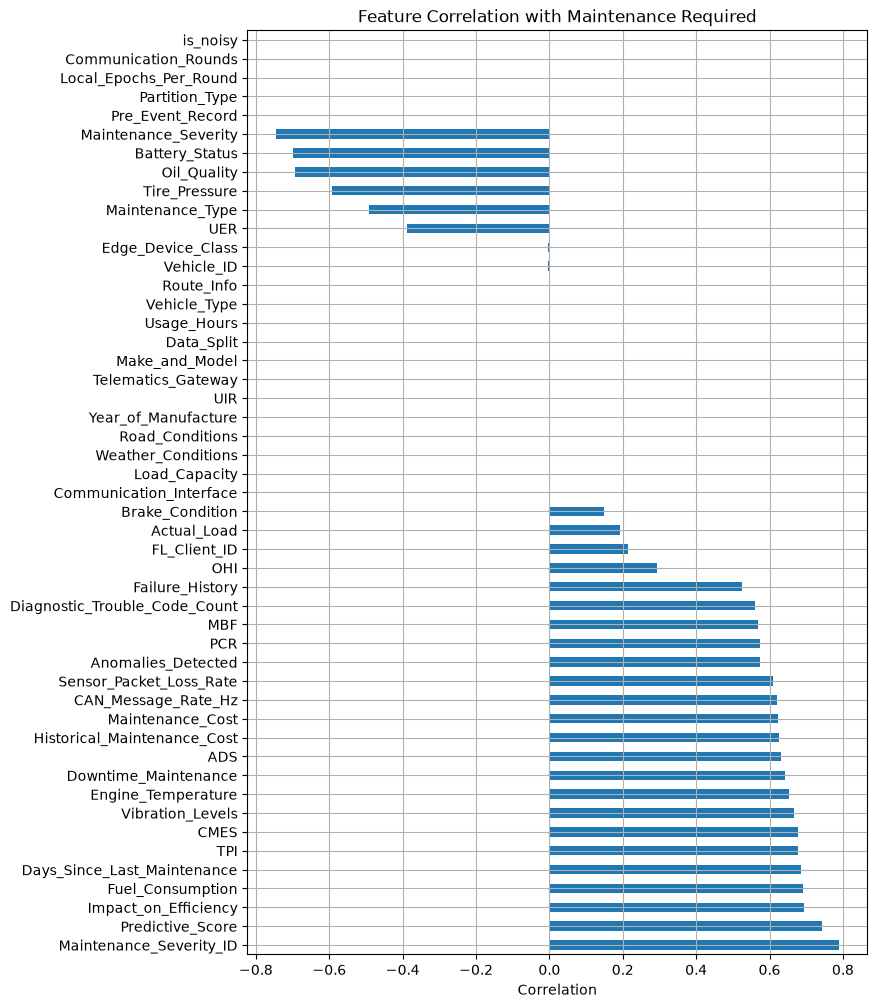

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,12))

target_corr.drop("Maintenance_Required").plot(kind="barh")

plt.title("Feature Correlation with Maintenance Required")
plt.xlabel("Correlation")
plt.grid(True)

plt.show()

In [4]:
suspected_leakage = pd.DataFrame({
    "Feature":[

        "Vehicle_ID",
        "Last_Maintenance_Date",

        "Predictive_Score",
        "PCR",
        "UIR",
        "TPI",
        "MBF",
        "ADS",
        "OHI",
        "CMES",
        "UER",

        "Maintenance_Cost",
        "Downtime_Maintenance",
        "Maintenance_Type",
        "Maintenance_Severity",
        "Maintenance_Severity_ID",

        "FL_Client_ID",
        "Partition_Type",
        "Local_Epochs_Per_Round",
        "Communication_Rounds",
        "Data_Split",

        "Pre_Event_Record"

    ],

    "Reason":[

        "Unique identifier",
        "Date information",

        "Derived prediction score",
        "Engineered metric",
        "Engineered metric",
        "Engineered metric",
        "Engineered metric",
        "Engineered metric",
        "Engineered metric",
        "Engineered metric",
        "Engineered metric",

        "Known after maintenance",
        "Known after maintenance",
        "Assigned after maintenance",
        "Target-related information",
        "Encoded target",

        "Federated Learning metadata",
        "Federated Learning metadata",
        "Federated Learning metadata",
        "Federated Learning metadata",
        "Dataset split information",

        "Experimental flag"
    ]
})

suspected_leakage

,Feature,Reason
0,Vehicle_ID,Unique identifier
1,Last_Maintenance_Date,Date information
2,Predictive_Score,Derived prediction score
3,PCR,Engineered metric
4,UIR,Engineered metric
5,TPI,Engineered metric
6,MBF,Engineered metric
7,ADS,Engineered metric
8,OHI,Engineered metric
9,CMES,Engineered metric


In [5]:
remove_features = suspected_leakage["Feature"].tolist()

df_clean = df.drop(columns=remove_features)

print("Original Shape :", df.shape)
print("After Removal :", df_clean.shape)

Original Shape : (250000, 51)
After Removal : (250000, 29)


In [6]:
print(df_clean.columns.tolist())

['Make_and_Model', 'Vehicle_Type', 'Year_of_Manufacture', 'Route_Info', 'Weather_Conditions', 'Road_Conditions', 'Communication_Interface', 'Telematics_Gateway', 'Edge_Device_Class', 'Usage_Hours', 'Load_Capacity', 'Actual_Load', 'Engine_Temperature', 'Tire_Pressure', 'Fuel_Consumption', 'Battery_Status', 'Vibration_Levels', 'Oil_Quality', 'Failure_History', 'Anomalies_Detected', 'Diagnostic_Trouble_Code_Count', 'CAN_Message_Rate_Hz', 'Sensor_Packet_Loss_Rate', 'Historical_Maintenance_Cost', 'Impact_on_Efficiency', 'Days_Since_Last_Maintenance', 'Brake_Condition', 'Maintenance_Required', 'is_noisy']


In [7]:
df_clean.to_csv(
    "data/processed/leakage_free_dataset.csv",
    index=False
)

print("Leakage-free dataset saved successfully!")

Leakage-free dataset saved successfully!


## Part 2: Feature Importance and Feature Selection
Using Random Forest importance to rank features and isolate the 20 primary predictive features.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

pd.set_option("display.max_columns", None)

plt.style.use("ggplot")

In [2]:
df = pd.read_csv("data/processed/leakage_free_dataset.csv")

print("Dataset Shape :", df.shape)

df.head()

Dataset Shape : (250000, 29)


,Make_and_Model,Vehicle_Type,Year_of_Manufacture,Route_Info,Weather_Conditions,Road_Conditions,Communication_Interface,Telematics_Gateway,Edge_Device_Class,Usage_Hours,Load_Capacity,Actual_Load,Engine_Temperature,Tire_Pressure,Fuel_Consumption,Battery_Status,Vibration_Levels,Oil_Quality,Failure_History,Anomalies_Detected,Diagnostic_Trouble_Code_Count,CAN_Message_Rate_Hz,Sensor_Packet_Loss_Rate,Historical_Maintenance_Cost,Impact_on_Efficiency,Days_Since_Last_Maintenance,Brake_Condition,Maintenance_Required,is_noisy
0,1,4,2016.118444,1,4,4,1,2,2,12881.926242,14610.712198,8523.579337,89.145434,39.899100,6.026211,90.127032,0.579184,82.438237,0.000000,0.000000,0.000000,43.118203,0.001724,202.088754,0.077322,41.783546,0,0,1
1,0,2,2016.595755,1,5,3,2,0,3,13372.449055,14172.717594,7749.402663,88.886942,36.978841,7.070288,99.537768,0.853223,89.370907,0.046148,1.313264,0.252539,40.338331,0.003628,497.679157,0.119995,55.151837,0,0,1
2,3,3,2011.291703,1,4,0,2,0,1,20207.584907,9930.144239,5760.589002,86.338994,37.620443,8.367029,80.463188,1.270297,91.042791,1.143310,0.000000,0.000000,28.488133,0.010269,418.393440,0.111623,65.390409,1,0,1
3,4,0,2020.365600,0,5,1,0,2,0,6525.182245,2399.728809,659.671711,98.122032,38.345444,8.434308,88.977012,1.867705,87.397523,0.073040,0.000000,0.083042,41.107644,0.006946,127.344090,0.085192,80.250621,1,0,1
4,4,1,2023.241627,1,4,2,2,2,3,1706.808162,5485.522822,1695.358238,92.107647,36.988619,8.043952,80.721200,1.282664,100.140464,1.027036,0.000000,0.953795,49.320925,0.009279,449.463507,0.079348,12.684568,1,0,1


In [3]:
X = df.drop("Maintenance_Required", axis=1)

y = df["Maintenance_Required"]

print("Features :", X.shape)
print("Target :", y.shape)

Features : (250000, 28)
Target : (250000,)


In [4]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [5]:
importance = pd.DataFrame({

    "Feature": X.columns,
    "Importance": rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
25,Days_Since_Last_Maintenance,0.189501
23,Historical_Maintenance_Cost,0.144875
24,Impact_on_Efficiency,0.110228
15,Battery_Status,0.090297
16,Vibration_Levels,0.082222
14,Fuel_Consumption,0.076591
17,Oil_Quality,0.066335
22,Sensor_Packet_Loss_Rate,0.033368
12,Engine_Temperature,0.033303
21,CAN_Message_Rate_Hz,0.021738


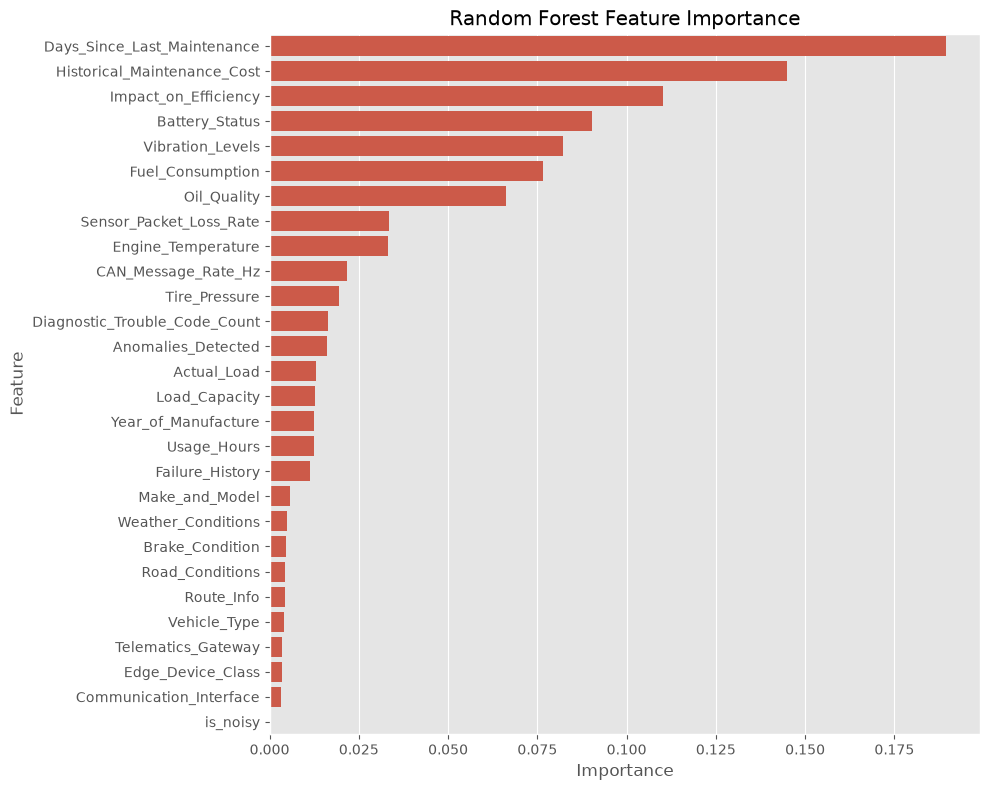

In [6]:
plt.figure(figsize=(10,8))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.tight_layout()

plt.show()

In [7]:
selected_features = [

    # Vehicle Information
    "Make_and_Model",
    "Vehicle_Type",
    "Year_of_Manufacture",

    # Road Analysis
    "Road_Conditions",
    "Weather_Conditions",
    "Route_Info",

    # Vehicle Usage
    "Usage_Hours",
    "Load_Capacity",
    "Actual_Load",

    # Engine Health
    "Engine_Temperature",
    "Fuel_Consumption",
    "Battery_Status",
    "Oil_Quality",
    "Vibration_Levels",
    "Tire_Pressure",

    # Diagnostics
    "Failure_History",
    "Anomalies_Detected",
    "Diagnostic_Trouble_Code_Count",
    "CAN_Message_Rate_Hz",
    "Sensor_Packet_Loss_Rate",

    # Target
    "Maintenance_Required"
]

In [8]:
final_df = df[selected_features]

print("Final Dataset Shape :", final_df.shape)

final_df.head()

Final Dataset Shape : (250000, 21)


,Make_and_Model,Vehicle_Type,Year_of_Manufacture,Road_Conditions,Weather_Conditions,Route_Info,Usage_Hours,Load_Capacity,Actual_Load,Engine_Temperature,Fuel_Consumption,Battery_Status,Oil_Quality,Vibration_Levels,Tire_Pressure,Failure_History,Anomalies_Detected,Diagnostic_Trouble_Code_Count,CAN_Message_Rate_Hz,Sensor_Packet_Loss_Rate,Maintenance_Required
0,1,4,2016.118444,4,4,1,12881.926242,14610.712198,8523.579337,89.145434,6.026211,90.127032,82.438237,0.579184,39.899100,0.000000,0.000000,0.000000,43.118203,0.001724,0
1,0,2,2016.595755,3,5,1,13372.449055,14172.717594,7749.402663,88.886942,7.070288,99.537768,89.370907,0.853223,36.978841,0.046148,1.313264,0.252539,40.338331,0.003628,0
2,3,3,2011.291703,0,4,1,20207.584907,9930.144239,5760.589002,86.338994,8.367029,80.463188,91.042791,1.270297,37.620443,1.143310,0.000000,0.000000,28.488133,0.010269,0
3,4,0,2020.365600,1,5,0,6525.182245,2399.728809,659.671711,98.122032,8.434308,88.977012,87.397523,1.867705,38.345444,0.073040,0.000000,0.083042,41.107644,0.006946,0
4,4,1,2023.241627,2,4,1,1706.808162,5485.522822,1695.358238,92.107647,8.043952,80.721200,100.140464,1.282664,36.988619,1.027036,0.000000,0.953795,49.320925,0.009279,0


In [9]:
print("Selected Features:\n")

for feature in final_df.columns[:-1]:
    print(feature)

Selected Features:

Make_and_Model
Vehicle_Type
Year_of_Manufacture
Road_Conditions
Weather_Conditions
Route_Info
Usage_Hours
Load_Capacity
Actual_Load
Engine_Temperature
Fuel_Consumption
Battery_Status
Oil_Quality
Vibration_Levels
Tire_Pressure
Failure_History
Anomalies_Detected
Diagnostic_Trouble_Code_Count
CAN_Message_Rate_Hz
Sensor_Packet_Loss_Rate


In [10]:
final_df.to_csv(
    "data/processed/final_selected_dataset.csv",
    index=False
)

print("Feature-selected dataset saved successfully!")

Feature-selected dataset saved successfully!


In [11]:
saved_df = pd.read_csv("data/processed/final_selected_dataset.csv")

print(saved_df.shape)

saved_df.head()

(250000, 21)


,Make_and_Model,Vehicle_Type,Year_of_Manufacture,Road_Conditions,Weather_Conditions,Route_Info,Usage_Hours,Load_Capacity,Actual_Load,Engine_Temperature,Fuel_Consumption,Battery_Status,Oil_Quality,Vibration_Levels,Tire_Pressure,Failure_History,Anomalies_Detected,Diagnostic_Trouble_Code_Count,CAN_Message_Rate_Hz,Sensor_Packet_Loss_Rate,Maintenance_Required
0,1,4,2016.118444,4,4,1,12881.926242,14610.712198,8523.579337,89.145434,6.026211,90.127032,82.438237,0.579184,39.899100,0.000000,0.000000,0.000000,43.118203,0.001724,0
1,0,2,2016.595755,3,5,1,13372.449055,14172.717594,7749.402663,88.886942,7.070288,99.537768,89.370907,0.853223,36.978841,0.046148,1.313264,0.252539,40.338331,0.003628,0
2,3,3,2011.291703,0,4,1,20207.584907,9930.144239,5760.589002,86.338994,8.367029,80.463188,91.042791,1.270297,37.620443,1.143310,0.000000,0.000000,28.488133,0.010269,0
3,4,0,2020.365600,1,5,0,6525.182245,2399.728809,659.671711,98.122032,8.434308,88.977012,87.397523,1.867705,38.345444,0.073040,0.000000,0.083042,41.107644,0.006946,0
4,4,1,2023.241627,2,4,1,1706.808162,5485.522822,1695.358238,92.107647,8.043952,80.721200,100.140464,1.282664,36.988619,1.027036,0.000000,0.953795,49.320925,0.009279,0
